In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression1
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

In [ ]:
from google.colab import files
import pandas as pd

# Upload CSV file
uploaded = files.upload()

Saving alzheimers_disease_data.csv to alzheimers_disease_data.csv


In [ ]:
# Load the dataset
df = pd.read_csv('alzheimers_disease_data.csv')

# Basic information about the dataset
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nBasic Statistics:")
print(df.describe())

Dataset Shape: (2149, 35)

First 5 rows:
   PatientID  Age  Gender  Ethnicity  EducationLevel        BMI  Smoking  \
0       4751   73       0          0               2  22.927749        0   
1       4752   89       0          0               0  26.827681        0   
2       4753   73       0          3               1  17.795882        0   
3       4754   74       1          0               1  33.800817        1   
4       4755   89       0          0               0  20.716974        0   

   AlcoholConsumption  PhysicalActivity  DietQuality  ...  MemoryComplaints  \
0           13.297218          6.327112     1.347214  ...                 0   
1            4.542524          7.619885     0.518767  ...                 0   
2           19.555085          7.844988     1.826335  ...                 0   
3           12.209266          8.428001     7.435604  ...                 0   
4           18.454356          6.310461     0.795498  ...                 0   

   BehavioralProblems      

In [ ]:
# Check for missing values
print("Missing values before cleaning:")
print(df.isnull().sum().sum())

# Replace missing values with mean for numerical columns
numerical_columns = df.select_dtypes(include=[np.number]).columns
imputer = SimpleImputer(strategy='mean')
df[numerical_columns] = imputer.fit_transform(df[numerical_columns])

print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

print(f"\nDataset shape after cleaning: {df.shape}")

Missing values before cleaning:
0

Missing values after cleaning:
0

Dataset shape after cleaning: (2149, 35)


In [ ]:
# Identify categorical columns (assuming they're object type or have few unique values)
categorical_columns = df.select_dtypes(include=['object']).columns

if len(categorical_columns) > 0:
    print("Categorical columns found:", list(categorical_columns))

    # Apply label encoding
    label_encoders = {}
    for col in categorical_columns:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le
        print(f"Encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")
else:
    print("No categorical columns found for encoding")

print(f"\nData types after encoding:\n{df.dtypes}")

Categorical columns found: ['DoctorInCharge']
Encoded DoctorInCharge: {'XXXConfid': np.int64(0)}

Data types after encoding:
PatientID                    float64
Age                          float64
Gender                       float64
Ethnicity                    float64
EducationLevel               float64
BMI                          float64
Smoking                      float64
AlcoholConsumption           float64
PhysicalActivity             float64
DietQuality                  float64
SleepQuality                 float64
FamilyHistoryAlzheimers      float64
CardiovascularDisease        float64
Diabetes                     float64
Depression                   float64
HeadInjury                   float64
Hypertension                 float64
SystolicBP                   float64
DiastolicBP                  float64
CholesterolTotal             float64
CholesterolLDL               float64
CholesterolHDL               float64
CholesterolTriglycerides     float64
MMSE                    

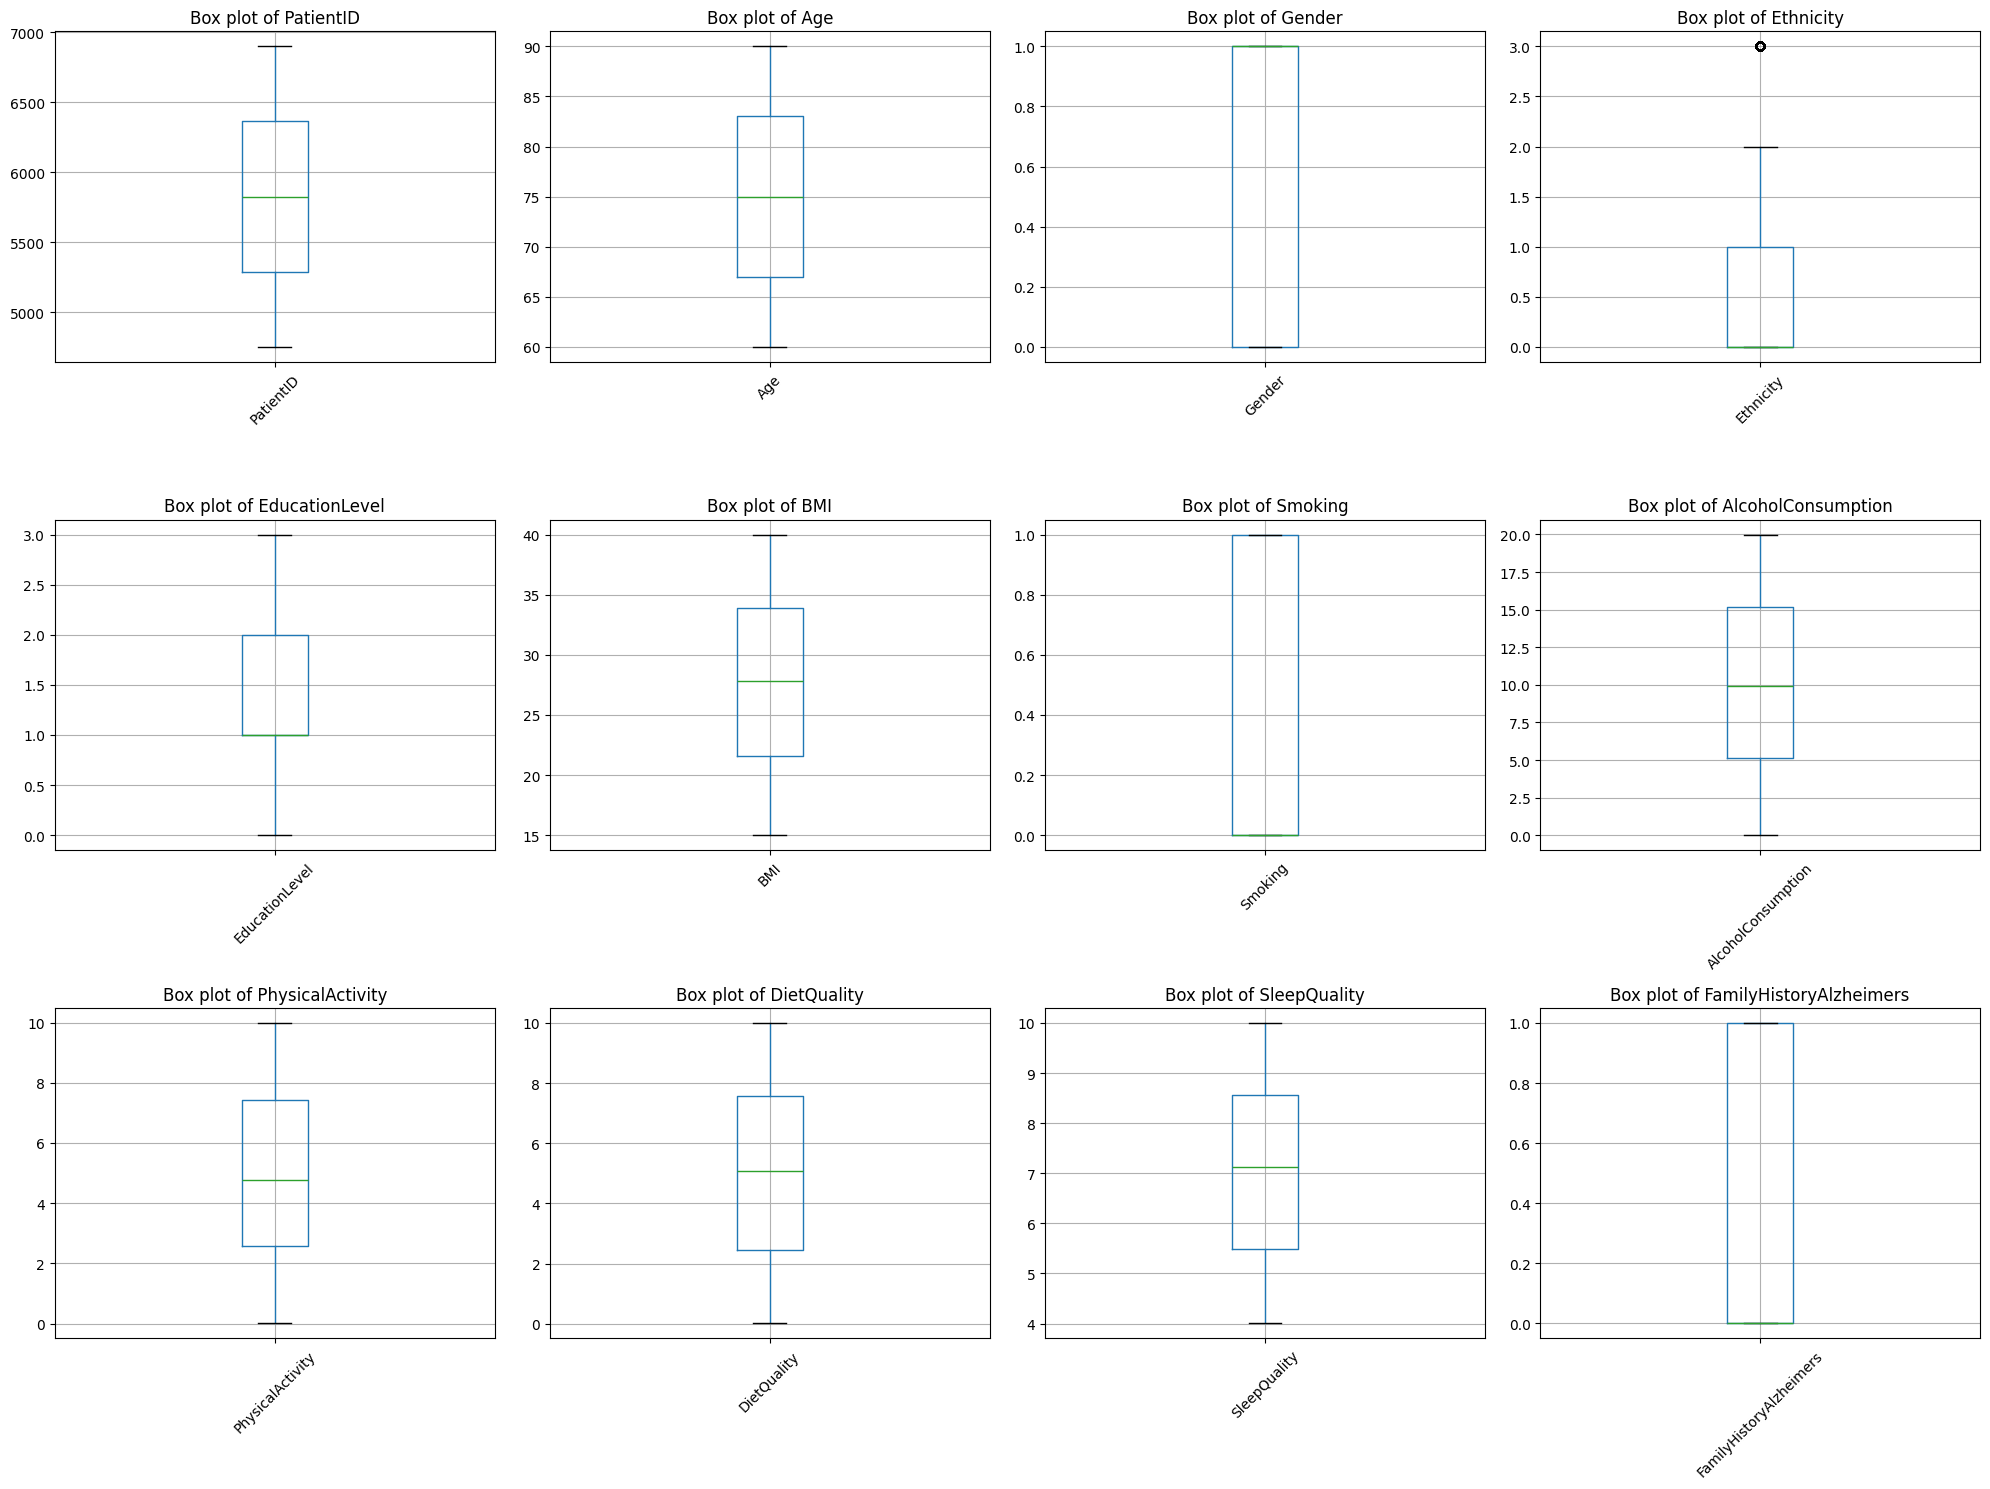

Outlier detection completed. Box plots show distribution of numerical features.


In [ ]:
# Select numerical features for outlier detection (excluding target variable if it exists)
numerical_features = df.select_dtypes(include=[np.number]).columns

# Create box plots for numerical features
plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_features[:12], 1):  # Plot first 12 features
    plt.subplot(3, 4, i)
    df.boxplot(column=col)
    plt.title(f'Box plot of {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("Outlier detection completed. Box plots show distribution of numerical features.")

In [ ]:
# Assuming 'Diagnosis' is the target variable - adjust if different
# Check if 'Diagnosis' column exists
if 'Diagnosis' in df.columns:
    target_column = 'Diagnosis'
else:
    # If 'Diagnosis' doesn't exist, use the last column as target (common in datasets)
    target_column = df.columns[-1]
    print(f"Using '{target_column}' as target variable")

# Separate features and target
X = df.drop(columns=[target_column])
y = df[target_column]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Target value counts:\n{y.value_counts()}")

Features shape: (2149, 34)
Target shape: (2149,)
Target value counts:
Diagnosis
0.0    1389
1.0     760
Name: count, dtype: int64


In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")
print(f"Training target distribution:\n{y_train.value_counts()}")
print(f"Testing target distribution:\n{y_test.value_counts()}")

Training set size: 1504
Testing set size: 645
Training target distribution:
Diagnosis
0.0    972
1.0    532
Name: count, dtype: int64
Testing target distribution:
Diagnosis
0.0    417
1.0    228
Name: count, dtype: int64


In [ ]:
# Scale the features for better model performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print(f"Scaled training data shape: {X_train_scaled.shape}")
print(f"Scaled testing data shape: {X_test_scaled.shape}")

Feature scaling completed!
Scaled training data shape: (1504, 34)
Scaled testing data shape: (645, 34)


In [ ]:
# Initialize and train logistic regression model
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")
print(f"Training accuracy: {logreg.score(X_train_scaled, y_train):.4f}")
print(f"Testing accuracy: {logreg.score(X_test_scaled, y_test):.4f}")

Logistic Regression model trained successfully!
Training accuracy: 0.8431
Testing accuracy: 0.8388


In [ ]:
# Perform cross-validation
cv_scores = cross_val_score(logreg, x, y, cv=5, scoring='accuracy')

print("Cross-validation scores:", cv_scores)
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Cross-validation scores: [0.85049834 0.81727575 0.84053156 0.80398671 0.86333333]
Mean CV accuracy: 0.8351 (+/- 0.0434)


In [ ]:
# Make predictions on test set
y_pred = logreg.predict(X_test_scaled)
y_pred_proba = logreg.predict_proba(X_test_scaled)[:, 1]  # Probability of positive class

print("Predictions completed!")
print(f"Sample predictions: {y_pred[:10]}")
print(f"Sample probabilities: {y_pred_proba[:10]}")

Predictions completed!
Sample predictions: [0. 0. 1. 1. 0. 1. 0. 0. 0. 0.]
Sample probabilities: [0.06182296 0.03659104 0.71469025 0.76721289 0.02964055 0.89711449
 0.24724494 0.01359392 0.25834233 0.04934953]


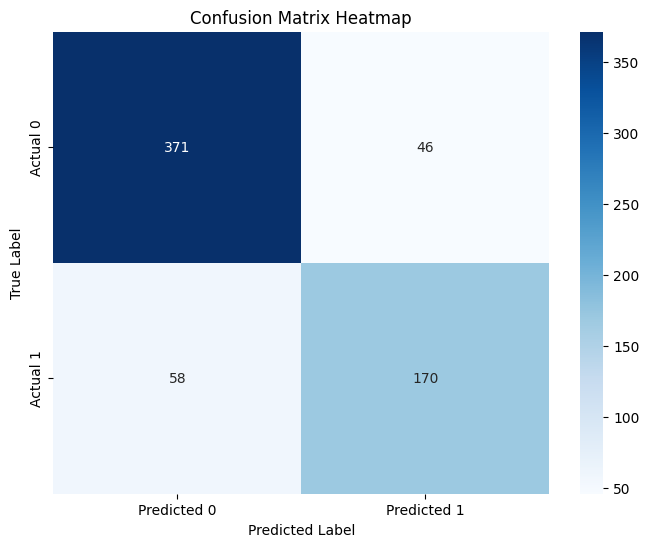

Confusion Matrix:
[[371  46]
 [ 58 170]]


In [ ]:
# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Predicted 0', 'Predicted 1'],
           yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix Heatmap')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print("Confusion Matrix:")
print(cm)

In [ ]:
# Generate classification report
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

         0.0       0.86      0.89      0.88       417
         1.0       0.79      0.75      0.77       228

    accuracy                           0.84       645
   macro avg       0.83      0.82      0.82       645
weighted avg       0.84      0.84      0.84       645



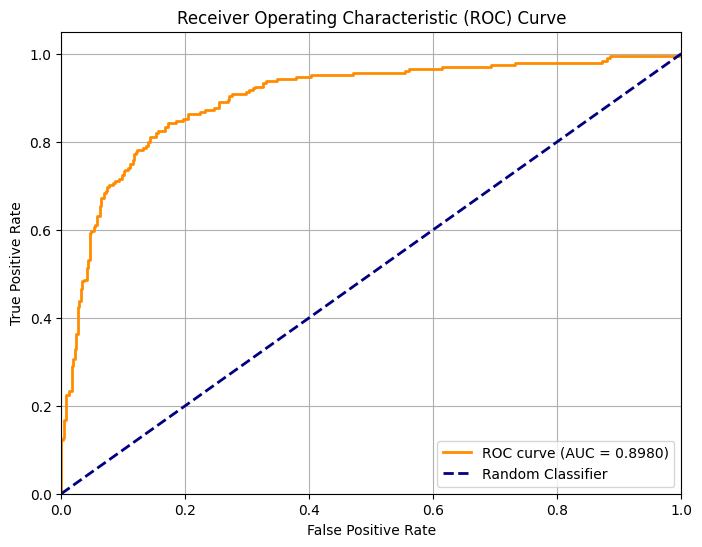

ROC AUC Score: 0.8980


In [ ]:
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"ROC AUC Score: {roc_auc:.4f}")

Top 10 Most Important Features:
                     feature  coefficient
24      FunctionalAssessment    -1.333480
27                       ADL    -1.262682
25          MemoryComplaints     1.100886
26        BehavioralProblems     0.929162
23                      MMSE    -0.881784
20            CholesterolLDL    -0.154033
22  CholesterolTriglycerides     0.125722
21            CholesterolHDL     0.117606
1                        Age    -0.107877
16              Hypertension     0.107120


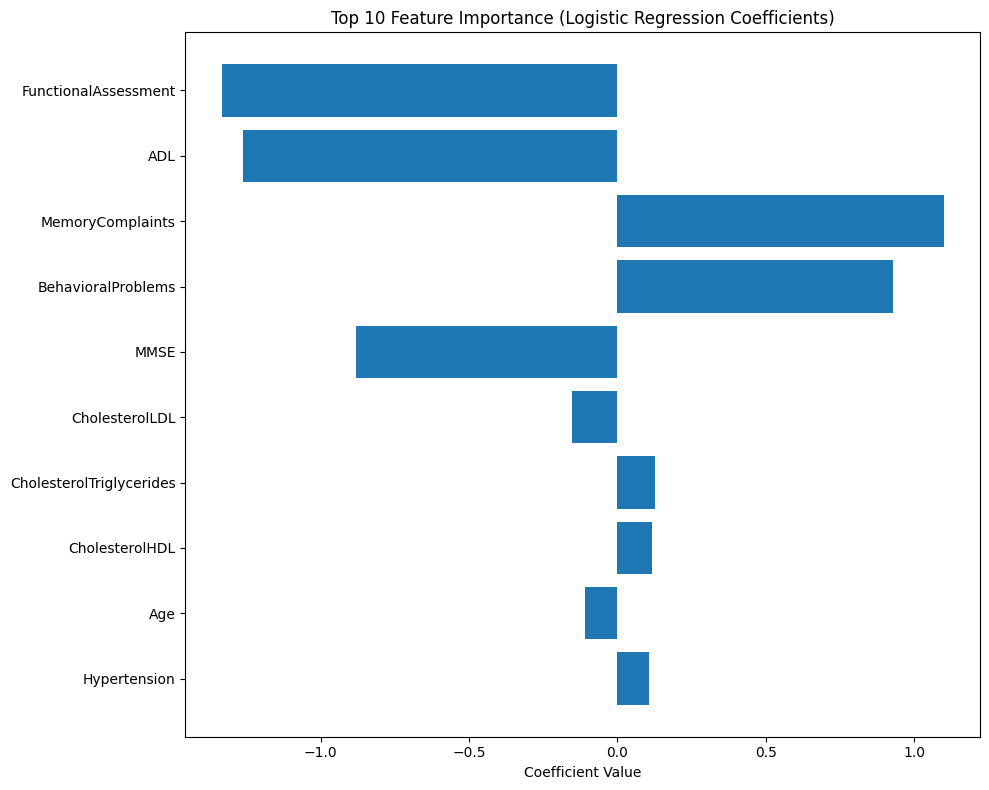

In [ ]:
# Analyze feature importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': logreg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 8))
top_features = feature_importance.head(10)
plt.barh(top_features['feature'], top_features['coefficient'])
plt.xlabel('Coefficient Value')
plt.title('Top 10 Feature Importance (Logistic Regression Coefficients)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
print("=" * 50)
print("MODEL PERFORMANCE SUMMARY")
print("=" * 50)
print(f"Training Accuracy: {logreg.score(X_train_scaled, y_train):.4f}")
print(f"Testing Accuracy: {logreg.score(X_test_scaled, y_test):.4f}")
print(f"Cross-Validation Mean Accuracy: {cv_scores.mean():.4f}")
print(f"ROC AUC Score: {roc_auc:.4f}")
print(f"Best Features: {list(feature_importance.head(5)['feature'].values)}")
print("=" * 50)

MODEL PERFORMANCE SUMMARY
Training Accuracy: 0.8431
Testing Accuracy: 0.8388
Cross-Validation Mean Accuracy: 0.8351
ROC AUC Score: 0.8980
Best Features: ['FunctionalAssessment', 'ADL', 'MemoryComplaints', 'BehavioralProblems', 'MMSE']
